In [1]:
import os
import sys
import pandas as pd
import scipy.stats

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
if 'google.colab' in str(get_ipython()): # running in colab
    !git clone --config lfs.fetchinclude="*"  https://github.com/sinc-lab/xvalRNAfolding.git
    DATA_PATH = './xvalRNAfolding/'
    # distance matrix, not in the repository (see the README)
    !mkdir -p ./xvalRNAfolding/data/archiveII/distances
    !curl -sL -o ./xvalRNAfolding/data/archiveII/distances/seqsim_f_all.h5 "https://drive.usercontent.google.com/download?export=download&confirm=t&id=1qLPI9ePyUksuJ7eu3Q8PV-kIMhC5NXDC"
else:
    DATA_PATH = '../'
sys.path.insert(0, DATA_PATH + "src")
from summaries import load_summary, read_split
FIG_PATH = DATA_PATH + "figures/archiveII/"


In [3]:
# sequence similarity matrix
SIM_PATH = DATA_PATH + "data/archiveII/distances/seqsim_f_all.h5" # not in the repository, see the README for the download link
sseq = pd.read_hdf(SIM_PATH)

In [4]:
# load partitions
partition_name = "sim_folds"
splits_sfold = read_split("archiveII", partition_name)

# load performances
summary_sfold = load_summary("archiveII", partition_name)

In [5]:
def get_test2train_similarity(sim_matrix, splits_sfold, sim, fold):
    selected_fold = splits_sfold[(splits_sfold["similarity"] == sim) & (splits_sfold["fold_number"] == fold)]
    test_ids  = sorted(selected_fold.loc[selected_fold["partition"] == "test", "id"])
    train_ids = sorted(selected_fold.loc[selected_fold["partition"] == "train", "id"])
    return sim_matrix.loc[test_ids, train_ids].copy()

In [6]:
def compute_sim_f1_all_folds(sim_matrix, splits_sfold, summary_sfold, method):
  boostrap_folds = summary_sfold.fold.unique()
  sim_f1_all_folds = {}

  for sim in splits_sfold.similarity.unique():
    all_f1_sim_data = []

    for fold in boostrap_folds:
      f1_test = summary_sfold.loc[(summary_sfold.similarity == sim) &
                                  (summary_sfold.method == method) &
                                  (summary_sfold.fold == fold)]

      # highest similarity to any train id
      sim_test = get_test2train_similarity(sim_matrix, splits_sfold, sim, fold)
      sim_test = sim_test.max(axis=1).to_frame(name='sim')

      merged_data = sim_test.merge(f1_test, how="inner", on="id")
      all_f1_sim_data.append(merged_data[['sim', 'f1']])

    sim_f1_all_folds[sim] = pd.concat(all_f1_sim_data, ignore_index=True)

  return sim_f1_all_folds

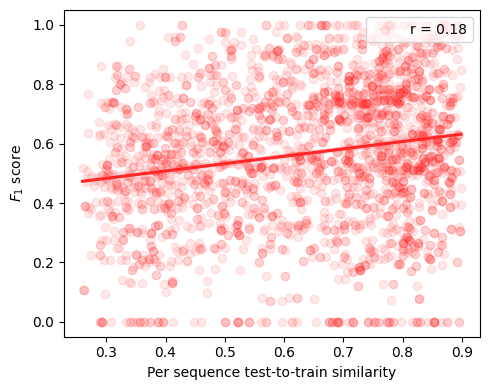

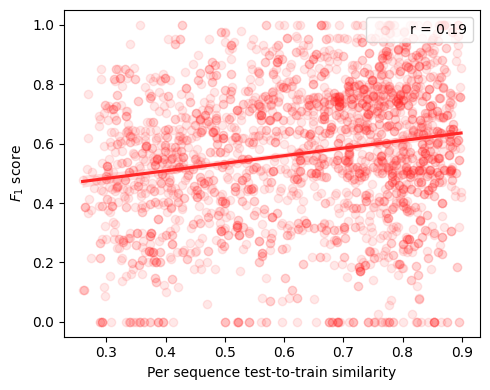

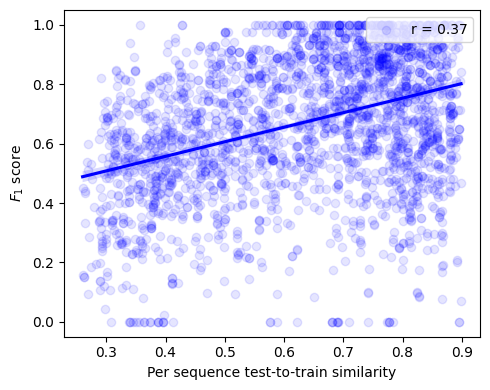

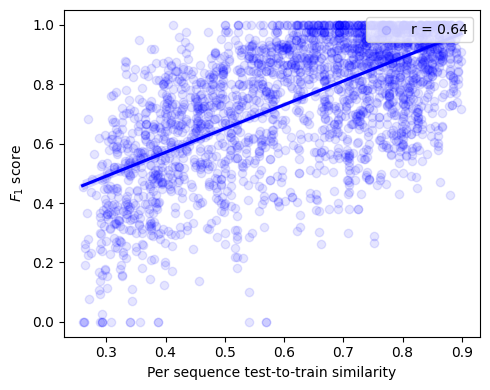

In [7]:
SIM = "sim90"
methods2plot = ["RNAfold", "LinearPartitionV", "MxFold2", "sincFold"]
method_colors = {
    "MxFold2": "#0000FF",
    "sincFold": "#0000FF",
    "RNAfold": "#FF2727",
    "LinearPartitionV": "#FF2727",
}

labels = {
    "MxFold2": "MXFold2",
    "sincFold": "sincFold",
    "RNAfold": "RNAfold",
    "LinearPartitionV": "LinearPartitionV",
}

sim90_f1_by_method = {}
for method in methods2plot:
  sim90_f1_by_method[method] = compute_sim_f1_all_folds(sseq, splits_sfold, summary_sfold, method)[SIM]

os.makedirs(FIG_PATH, exist_ok=True)

for method in methods2plot:
  sim_f1_data = sim90_f1_by_method[method]

  r, _ = scipy.stats.pearsonr(sim_f1_data['sim'], sim_f1_data['f1'])
  color = method_colors[method]

  fig, ax = plt.subplots(figsize=(5, 4))
  sns.regplot(x=sim_f1_data['sim'], y=sim_f1_data['f1'],
              scatter_kws={'marker': '.', 'alpha': 0.1, 'color': color},
              line_kws={'color': color},
              label=f"r = {r:.2f}",
              ax=ax)

  ax.legend(loc="upper right")
  ax.set_xlabel("Per sequence test-to-train similarity")
  ax.set_ylabel("$F_1$ score")

  fig.tight_layout()
  fig.savefig(FIG_PATH + f"Fig_S6_{method}.pdf", bbox_inches='tight', dpi=300)